LOADING LIBRARIES

In [ ]:
import os
import json
import rasterio
from rasterio.windows import Window
import geopandas as gpd
from shapely.geometry import box
from tqdm import tqdm

In [ ]:
!pip install torch torchvision pycocotools segmentation-models-pytorch albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [ ]:
!pip install torch torchvision torchaudio --extra-index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu118


**Verifying the building data has everything i need**

# **1. INPUT DATA**

In [ ]:
import geopandas as gpd

BUILDINGS = "/content/drive/MyDrive/Image data/Ground truth digitized data/building sample.shp"

gdf = gpd.read_file(BUILDINGS)

print("Rows:", len(gdf))
print("CRS:", gdf.crs)
print("Geometry types:")
print(gdf.geom_type.value_counts())

print("\nFirst 5 rows:")
print(gdf.head())

Rows: 4194
CRS: EPSG:4326
Geometry types:
Polygon         4187
MultiPolygon       7
Name: count, dtype: int64

First 5 rows:
   fid label    area_m2                                           geometry
0  1.0  None  39.434711  POLYGON ((28.09788 -25.72611, 28.09793 -25.726...
1  2.0  None  30.416853  POLYGON ((28.09785 -25.72646, 28.0979 -25.7264...
2  3.0  None  47.752239  POLYGON ((28.09819 -25.72619, 28.0982 -25.7261...
3  4.0  None  43.315271  POLYGON ((28.09822 -25.72645, 28.09824 -25.726...
4  5.0  None  24.461776  POLYGON ((28.09821 -25.72633, 28.09823 -25.726...


# **2. PRE PROCESSING**

*Cleaning the building*

if there are any empty or null geometries

In [ ]:
import geopandas as gpd
from shapely.validation import make_valid

INPUT_BUILDINGS = "/content/drive/MyDrive/Image data/Ground truth digitized data/building sample.shp"

OUTPUT_BUILDINGS = "/content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg"

gdf = gpd.read_file(INPUT_BUILDINGS)

print("Original count:", len(gdf))

# Remove null geometries
gdf = gdf[gdf.geometry.notnull()]

# Remove empty geometries
gdf = gdf[~gdf.geometry.is_empty]

# Repair invalid geometries
gdf["geometry"] = gdf.geometry.apply(make_valid)

# Explode multipolygons
gdf = gdf.explode(index_parts=False)

# Keep polygons only
gdf = gdf[gdf.geom_type == "Polygon"]

# Remove duplicate geometries
gdf["wkt"] = gdf.geometry.to_wkt()
gdf = gdf.drop_duplicates(subset="wkt")
gdf = gdf.drop(columns="wkt")

# Create building ID
gdf["building_id"] = range(1, len(gdf) + 1)

# Drop the original 'fid' column to avoid conflict with GPKG driver's internal 'fid'
if "fid" in gdf.columns:
    gdf = gdf.drop(columns=["fid"])

print("Final count:", len(gdf))

if len(gdf) == 0:
    raise ValueError("No buildings remain after cleaning.")

gdf.to_file(
    OUTPUT_BUILDINGS,
    driver="GPKG"
)

print("Saved:", OUTPUT_BUILDINGS)

Original count: 4194
Final count: 4201
Saved: /content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg


In [ ]:
import geopandas as gpd

gdf = gpd.read_file(
    "/content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg"
)

print("Rows:", len(gdf))
print("CRS:", gdf.crs)
print(gdf.columns)

Rows: 4201
CRS: EPSG:4326
Index(['label', 'area_m2', 'building_id', 'geometry'], dtype='object')


# **3.MASK GENERATION**

*Creating building masks for deeplab*

---



In [ ]:
# ==========================================================
# 02_create_building_masks.py
# Building Footprints -> Binary Raster Mask
# ==========================================================

import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import numpy as np

# ==========================================================
# USER SETTINGS
# ==========================================================

ORTHO_PATH = "/content/drive/MyDrive/Image data/Melusi Drone imagery/Malusi clipped.tif"

BUILDINGS_PATH = "/content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg"

OUTPUT_MASK = "/content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif"

# ==========================================================
# LOAD BUILDINGS
# ==========================================================

print("Loading building footprints...")

gdf = gpd.read_file(BUILDINGS_PATH)

print(f"Buildings loaded: {len(gdf)}")

if len(gdf) == 0:
    raise ValueError(
        "No building footprints found. Check the input layer."
    )

# ==========================================================
# OPEN ORTHOMOSAIC
# ==========================================================

with rasterio.open(ORTHO_PATH) as src:

    transform = src.transform
    crs = src.crs
    width = src.width
    height = src.height

    profile = src.profile.copy()

print(f"Raster size: {width} x {height}")
print(f"Raster CRS: {crs}")

# ==========================================================
# CRS CHECK
# ==========================================================

if gdf.crs != crs:

    print("Reprojecting footprints...")

    gdf = gdf.to_crs(crs)

# ==========================================================
# PREPARE SHAPES
# ==========================================================

shapes = (
    (geom, 1)
    for geom in gdf.geometry
)

# ==========================================================
# RASTERIZE
# ==========================================================

print("Creating mask...")

mask = rasterize(
    shapes=shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    default_value=1,
    dtype=np.uint8
)

# ==========================================================
# SAVE MASK
# ==========================================================

profile.update(
    count=1,
    dtype=rasterio.uint8,
    compress="lzw"
)

with rasterio.open(
    OUTPUT_MASK,
    "w",
    **profile
) as dst:

    dst.write(mask, 1)

print("Mask created successfully.")
print(f"Saved: {OUTPUT_MASK}")

Loading building footprints...
Buildings loaded: 4201
Raster size: 31636 x 10056
Raster CRS: EPSG:4326
Creating mask...


Mask created successfully.
Saved: /content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif


In [ ]:
import rasterio

with rasterio.open(
    "/content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif"
) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("CRS:", src.crs)
    print("Bands:", src.count)
    print("Data Type:", src.dtypes[0])

Width: 31636
Height: 10056
CRS: EPSG:4326
Bands: 1
Data Type: uint8


In [ ]:
import rasterio
import numpy as np

unique_values = set()

with rasterio.open(
    "/content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif"
) as src:

    for _, window in src.block_windows(1):

        data = src.read(1, window=window)

        unique_values.update(
            np.unique(data)
        )

print(unique_values)

# **4. Tile Generation**

*Creating one tile from Aerial image*

this is to test training data on one image tile first before doing it for the entire study area

In [ ]:
import rasterio

with rasterio.open(
    "/content/drive/MyDrive/Image data/Melusi Drone imagery/Malusi clipped.tif"
) as src:

    print("Bands:", src.count)

    for i in range(1, src.count + 1):
        print(f"Band {i} dtype:", src.dtypes[i-1])

    print("Bounds:", src.bounds)


In [ ]:
# ==========================================================
# 03_generate_single_test_tile.py
# Create One Test Tile for Pipeline Validation
# ==========================================================

import geopandas as gpd
import rasterio
from rasterio.windows import Window
from shapely.geometry import box

# ==========================================================
# USER SETTINGS
# ==========================================================

ORTHO_PATH = "/content/drive/MyDrive/Image data/Melusi Drone imagery/Malusi clipped.tif"

MASK_PATH = "/content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif"

BUILDINGS_PATH = "/content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg"

OUTPUT_TILE = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_tile.tif"

OUTPUT_MASK = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_mask.tif"

OUTPUT_BUILDINGS = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_buildings.gpkg"

TILE_SIZE = 1024

# ==========================================================
# LOAD BUILDINGS
# ==========================================================

gdf = gpd.read_file(BUILDINGS_PATH)

print("Buildings:", len(gdf))

# ==========================================================
# FIND BUILDING CENTROID
# ==========================================================

centroid = gdf.unary_union.centroid

# ==========================================================
# OPEN ORTHO
# ==========================================================

with rasterio.open(ORTHO_PATH) as src:

    row, col = src.index(
        centroid.x,
        centroid.y
    )

    half = TILE_SIZE // 2

    col_start = max(0, col - half)
    row_start = max(0, row - half)

    window = Window(
        col_start,
        row_start,
        TILE_SIZE,
        TILE_SIZE
    )

    tile = src.read(window=window)

    profile = src.profile.copy()

    profile.update(
        width=TILE_SIZE,
        height=TILE_SIZE,
        transform=rasterio.windows.transform(
            window,
            src.transform
        )
    )

    with rasterio.open(
        OUTPUT_TILE,
        "w",
        **profile
    ) as dst:

        dst.write(tile)

print("Orthomosaic tile saved")

# ==========================================================
# TILE MASK
# ==========================================================

with rasterio.open(MASK_PATH) as src:

    mask_tile = src.read(
        window=window
    )

    profile = src.profile.copy()

    profile.update(
        width=TILE_SIZE,
        height=TILE_SIZE,
        transform=rasterio.windows.transform(
            window,
            src.transform
        )
    )

    with rasterio.open(
        OUTPUT_MASK,
        "w",
        **profile
    ) as dst:

        dst.write(mask_tile)

print("Mask tile saved")

# ==========================================================
# CLIP BUILDINGS TO TILE
# ==========================================================

with rasterio.open(OUTPUT_TILE) as src:

    bounds = src.bounds

tile_poly = box(
    bounds.left,
    bounds.bottom,
    bounds.right,
    bounds.top
)

tile_gdf = gpd.GeoDataFrame(
    geometry=[tile_poly],
    crs=gdf.crs
)

clipped = gpd.overlay(
    gdf,
    tile_gdf,
    how="intersection"
)

clipped.to_file(
    OUTPUT_BUILDINGS,
    driver="GPKG"
)

print("Buildings inside tile:", len(clipped))

print("Done.")

In [ ]:
import geopandas as gpd

gdf = gpd.read_file(
    "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_buildings.gpkg"
)

print("Buildings in tile:", len(gdf))

In [ ]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(
    "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_tile.tif"
) as src:

    img = src.read([1,2,3])

img = np.transpose(img, (1,2,0))

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.axis("off")
plt.show()

# **5. COCO GENERATION**

*This is only for one image tile generated above*

In [ ]:
# ==========================================================
# 04_generate_coco.py
# Tile Buildings -> COCO Annotations
# ==========================================================

import geopandas as gpd
import rasterio
import json

# ==========================================================
# INPUTS
# ==========================================================

TILE_PATH = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_tile.tif"

BUILDINGS_PATH = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_buildings.gpkg"

OUTPUT_JSON = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_coco.json"

# ==========================================================
# LOAD DATA
# ==========================================================

gdf = gpd.read_file(BUILDINGS_PATH)

with rasterio.open(TILE_PATH) as src:

    transform = src.transform
    width = src.width
    height = src.height

# ==========================================================
# COCO STRUCTURE
# ==========================================================

coco = {

    "images": [],
    "annotations": [],
    "categories": [
        {
            "id": 1,
            "name": "building",
            "supercategory": "building"
        }
    ]
}

# ==========================================================
# IMAGE ENTRY
# ==========================================================

coco["images"].append({

    "id": 1,
    "file_name": "test_tile.tif",
    "width": width,
    "height": height
})

# ==========================================================
# ANNOTATIONS
# ==========================================================

annotation_id = 1

for idx, row in gdf.iterrows():

    geom = row.geometry

    if geom.is_empty:
        continue

    x, y = geom.exterior.coords.xy

    pixel_coords = []

    for xx, yy in zip(x, y):

        row_px, col_px = rasterio.transform.rowcol(
            transform,
            xx,
            yy
        )

        pixel_coords.extend(
            [float(col_px), float(row_px)]
        )

    minx, miny, maxx, maxy = geom.bounds

    row1, col1 = rasterio.transform.rowcol(
        transform,
        minx,
        maxy
    )

    row2, col2 = rasterio.transform.rowcol(
        transform,
        maxx,
        miny
    )

    bbox_width = abs(col2 - col1)
    bbox_height = abs(row2 - row1)

    coco["annotations"].append({

        "id": annotation_id,

        "image_id": 1,

        "category_id": 1,

        "segmentation": [pixel_coords],

        "bbox": [
            float(min(col1, col2)),
            float(min(row1, row2)),
            float(bbox_width),
            float(bbox_height)
        ],

        "area": float(row["area_m2"]),

        "iscrowd": 0
    })

    annotation_id += 1

# ==========================================================
# SAVE
# ==========================================================

with open(
    OUTPUT_JSON,
    "w"
) as f:

    json.dump(
        coco,
        f,
        indent=2
    )

print("Annotations:", len(coco["annotations"]))
print("Saved:", OUTPUT_JSON)

In [ ]:
import json

with open(
    "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_coco.json"
) as f:

    coco = json.load(f)

print("Images:", len(coco["images"]))
print("Annotations:", len(coco["annotations"]))

print(coco["annotations"][0])

*Visualizing whether the Coco polygons align with the rooftops or are they offset*

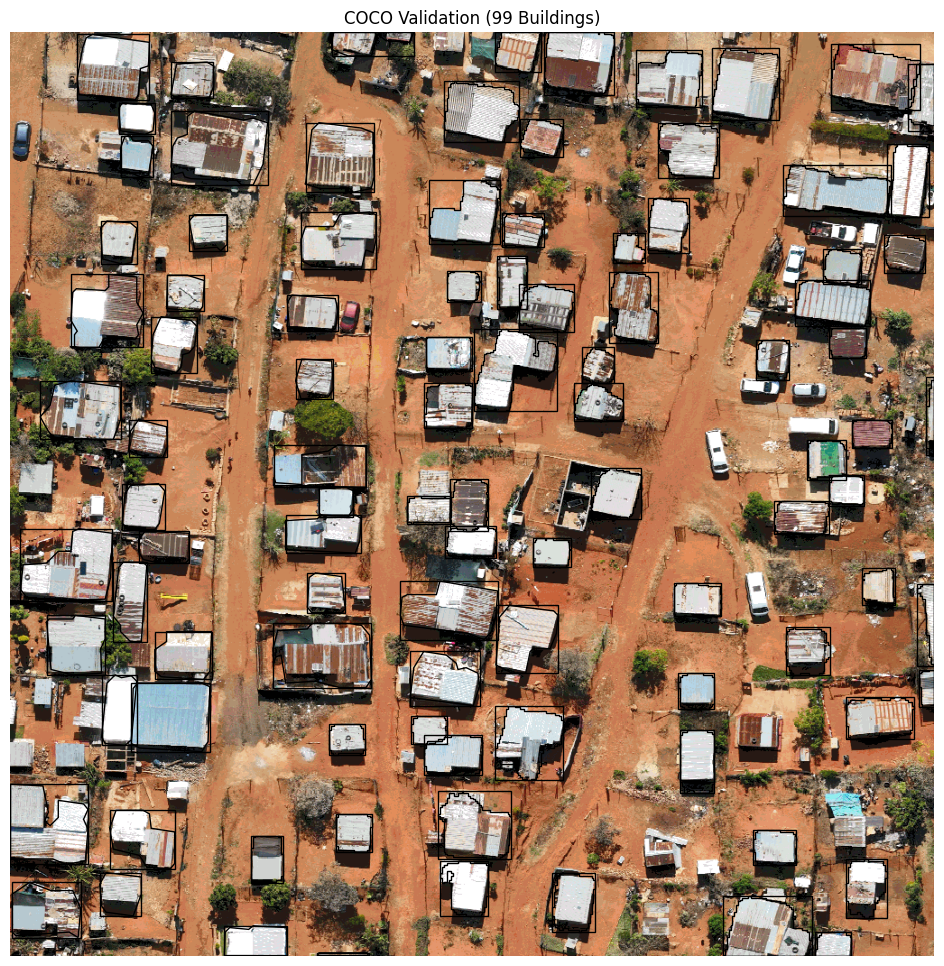

In [ ]:
import json
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.patches import Rectangle


# INPUTS


IMAGE_PATH = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_tile.tif"

COCO_PATH = "/content/drive/MyDrive/Image data/Tiles/Test Tile/test_coco.json"


# LOAD IMAGE


with rasterio.open(IMAGE_PATH) as src:

    rgb = src.read([1,2,3])

rgb = np.transpose(rgb, (1,2,0))


# LOAD COCO


with open(COCO_PATH) as f:
    coco = json.load(f)


# DISPLAY


fig, ax = plt.subplots(
    figsize=(12,12)
)

ax.imshow(rgb)


# DRAW POLYGONS + BBOXES


for ann in coco["annotations"]:

    seg = ann["segmentation"][0]

    points = np.array(seg).reshape(-1,2)

    poly = Polygon(
        points,
        fill=False,
        linewidth=1
    )

    ax.add_patch(poly)

    x, y, w, h = ann["bbox"]

    rect = Rectangle(
        (x,y),
        w,
        h,
        fill=False,
        linewidth=1
    )

    ax.add_patch(rect)

ax.set_title(
    f"COCO Validation ({len(coco['annotations'])} Buildings)"
)

ax.axis("off")

plt.show()

*Tile generation but this time for the whole study area*

In [ ]:
# ==========================================================
# 03_generate_tiles.py
# Research Dataset Generation
# ==========================================================

import os
import geopandas as gpd
import rasterio

from rasterio.windows import Window
from shapely.geometry import box

# ==========================================================
# USER SETTINGS
# ==========================================================

ORTHO_PATH = "/content/drive/MyDrive/Image data/Melusi Drone imagery/Malusi clipped.tif"

MASK_PATH = "/content/drive/MyDrive/Image data/DeepLab Masks/building_mask.tif"

BUILDINGS_PATH = "/content/drive/MyDrive/Image data/Ground truth digitized data/buildings_clean.gpkg"

OUTPUT_ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles"

TILE_SIZE = 1024
OVERLAP = 0.40

STRIDE = int(
    TILE_SIZE * (1 - OVERLAP)
)

MIN_BUILDINGS = 5

# ==========================================================
# CREATE FOLDERS
# ==========================================================

IMAGE_DIR = os.path.join(
    OUTPUT_ROOT,
    "images"
)

MASK_DIR = os.path.join(
    OUTPUT_ROOT,
    "masks"
)

VECTOR_DIR = os.path.join(
    OUTPUT_ROOT,
    "vectors"
)

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(VECTOR_DIR, exist_ok=True)

# ==========================================================
# LOAD BUILDINGS
# ==========================================================

gdf = gpd.read_file(
    BUILDINGS_PATH
)

print(
    f"Buildings loaded: {len(gdf)}"
)

# ==========================================================
# OPEN RASTERS
# ==========================================================

ortho = rasterio.open(
    ORTHO_PATH
)

mask = rasterio.open(
    MASK_PATH
)

width = ortho.width
height = ortho.height

tile_id = 0

# ==========================================================
# LOOP THROUGH IMAGE
# ==========================================================

for row in range(
    0,
    height - TILE_SIZE,
    STRIDE
):

    for col in range(
        0,
        width - TILE_SIZE,
        STRIDE
    ):

        window = Window(
            col,
            row,
            TILE_SIZE,
            TILE_SIZE
        )

        transform = rasterio.windows.transform(
            window,
            ortho.transform
        )

        bounds = rasterio.windows.bounds(
            window,
            ortho.transform
        )

        tile_poly = box(
            bounds[0],
            bounds[1],
            bounds[2],
            bounds[3]
        )

        tile_extent = gpd.GeoDataFrame(
            geometry=[tile_poly],
            crs=gdf.crs
        )

        clipped = gpd.overlay(
            gdf,
            tile_extent,
            how="intersection"
        )

        if len(clipped) < MIN_BUILDINGS:
            continue

        tile_id += 1

        name = f"tile_{tile_id:06d}"

        # =====================================
        # RGB IMAGE
        # =====================================

        image = ortho.read(
            [1,2,3],
            window=window
        )

        image_profile = ortho.profile.copy()

        image_profile.update(
            count=3,
            width=TILE_SIZE,
            height=TILE_SIZE,
            transform=transform
        )

        image_path = os.path.join(
            IMAGE_DIR,
            f"{name}.tif"
        )

        with rasterio.open(
            image_path,
            "w",
            **image_profile
        ) as dst:

            dst.write(image)

        # =====================================
        # MASK
        # =====================================

        mask_data = mask.read(
            1,
            window=window
        )

        mask_profile = mask.profile.copy()

        mask_profile.update(
            count=1,
            width=TILE_SIZE,
            height=TILE_SIZE,
            transform=transform
        )

        mask_path = os.path.join(
            MASK_DIR,
            f"{name}_mask.tif"
        )

        with rasterio.open(
            mask_path,
            "w",
            **mask_profile
        ) as dst:

            dst.write(
                mask_data,
                1
            )

        # =====================================
        # VECTOR
        # =====================================

        vector_path = os.path.join(
            VECTOR_DIR,
            f"{name}.gpkg"
        )

        clipped.to_file(
            vector_path,
            driver="GPKG"
        )

print(
    f"\nFinished."
)

print(
    f"Tiles created: {tile_id}"
)

In [ ]:
import os
import geopandas as gpd

VECTOR_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/vectors"

counts = []

for f in os.listdir(VECTOR_DIR):

    if f.endswith(".gpkg"):

        gdf = gpd.read_file(
            os.path.join(VECTOR_DIR, f)
        )

        counts.append(len(gdf))

print("Tiles:", len(counts))
print("Min buildings:", min(counts))
print("Max buildings:", max(counts))
print("Average buildings:", sum(counts)/len(counts))

# **6. TRAIN/TEST SPLIT**

In [ ]:
# ==========================================================
# 04_split_dataset.py
# 70 / 10 / 20 Split
# ==========================================================

import os
import shutil
import random

# ==========================================================
# SETTINGS
# ==========================================================

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles"

IMAGE_DIR = os.path.join(ROOT, "images")
MASK_DIR = os.path.join(ROOT, "masks")
VECTOR_DIR = os.path.join(ROOT, "vectors")

OUTPUT_ROOT = os.path.join(ROOT, "Dataset_Split")

SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO = 0.10
TEST_RATIO = 0.20

# ==========================================================
# CREATE FOLDERS
# ==========================================================

for split in ["train", "val", "test"]:

    os.makedirs(
        os.path.join(OUTPUT_ROOT, split, "images"),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(OUTPUT_ROOT, split, "masks"),
        exist_ok=True
    )

    os.makedirs(
        os.path.join(OUTPUT_ROOT, split, "vectors"),
        exist_ok=True
    )

# ==========================================================
# GET TILE IDS
# ==========================================================

tiles = sorted([

    f.replace(".tif", "")

    for f in os.listdir(IMAGE_DIR)

    if f.endswith(".tif")

])

random.seed(SEED)
random.shuffle(tiles)

n = len(tiles)

n_train = int(n * TRAIN_RATIO)
n_val = int(n * VAL_RATIO)

train_tiles = tiles[:n_train]
val_tiles = tiles[n_train:n_train+n_val]
test_tiles = tiles[n_train+n_val:]

print("Train:", len(train_tiles))
print("Val:", len(val_tiles))
print("Test:", len(test_tiles))

# ==========================================================
# COPY FILES
# ==========================================================

def copy_split(tile_list, split_name):

    for tile in tile_list:

        shutil.copy2(
            os.path.join(
                IMAGE_DIR,
                tile + ".tif"
            ),
            os.path.join(
                OUTPUT_ROOT,
                split_name,
                "images"
            )
        )

        shutil.copy2(
            os.path.join(
                MASK_DIR,
                tile + "_mask.tif"
            ),
            os.path.join(
                OUTPUT_ROOT,
                split_name,
                "masks"
            )
        )

        shutil.copy2(
            os.path.join(
                VECTOR_DIR,
                tile + ".gpkg"
            ),
            os.path.join(
                OUTPUT_ROOT,
                split_name,
                "vectors"
            )
        )

copy_split(train_tiles, "train")
copy_split(val_tiles, "val")
copy_split(test_tiles, "test")

print("Dataset split complete.")

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

for split in ["train","val","test"]:

    imgs = len(
        os.listdir(
            os.path.join(ROOT, split, "images")
        )
    )

    masks = len(
        os.listdir(
            os.path.join(ROOT, split, "masks")
        )
    )

    vectors = len(
        os.listdir(
            os.path.join(ROOT, split, "vectors")
        )
    )

    print(split)
    print(" Images:", imgs)
    print(" Masks :", masks)
    print(" Vectors:", vectors)
    print()

# **7. DEEPLAB V3+**

In [ ]:
import os
import rasterio
import numpy as np

MASK_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/masks"

unique_values = set()

for f in os.listdir(MASK_DIR):

    if f.endswith(".tif"):

        with rasterio.open(
            os.path.join(MASK_DIR, f)
        ) as src:

            data = src.read(1)

            unique_values.update(
                np.unique(data)
            )

print(unique_values)

In [ ]:
import os
import rasterio

IMAGE_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/images"

sample = sorted(os.listdir(IMAGE_DIR))[0]

with rasterio.open(
    os.path.join(IMAGE_DIR, sample)
) as src:

    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)

*Creating deeplab dataset*

In [ ]:
# ==========================================================
# 06_create_deeplab_dataset.py
# DeepLabV3+ Dataset Loader
# ==========================================================

import os
import numpy as np
import rasterio

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# ==========================================================
# SETTINGS
# ==========================================================

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

# ==========================================================
# DATASET CLASS
# ==========================================================

class BuildingDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".tif")
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        mask_name = image_name.replace(
            ".tif",
            "_mask.tif"
        )

        # -----------------------------------
        # IMAGE
        # -----------------------------------

        with rasterio.open(
            os.path.join(
                self.image_dir,
                image_name
            )
        ) as src:

            image = src.read()

        image = image.astype(
            np.float32
        ) / 255.0

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        # -----------------------------------
        # MASK
        # -----------------------------------

        with rasterio.open(
            os.path.join(
                self.mask_dir,
                mask_name
            )
        ) as src:

            mask = src.read(1)

        mask = torch.tensor(
            mask,
            dtype=torch.long
        )

        return image, mask

# ==========================================================
# DATASETS
# ==========================================================

train_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "train/images"
    ),

    os.path.join(
        ROOT,
        "train/masks"
    )
)

val_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "val/images"
    ),

    os.path.join(
        ROOT,
        "val/masks"
    )
)

test_dataset = BuildingDataset(

    os.path.join(
        ROOT,
        "test/images"
    ),

    os.path.join(
        ROOT,
        "test/masks"
    )
)

# ==========================================================
# DATALOADERS
# ==========================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2
)

# ==========================================================
# VALIDATION
# ==========================================================

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

images, masks = next(
    iter(train_loader)
)

print()

print("Image tensor:")
print(images.shape)

print()

print("Mask tensor:")
print(masks.shape)

print()

print("Image range:")
print(images.min().item(),
      images.max().item())

print()

print("Mask classes:")
print(torch.unique(masks))

In [ ]:
!pip install -q segmentation-models-pytorch
!pip install -q torchmetrics

In [ ]:
import torch
import torchvision

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

In [ ]:
import segmentation_models_pytorch as smp

print("SMP:", smp.__version__)

*Creating the folders for my deeplab model outputs*

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Image data/DeepLab outputs"

folders = [
    "models",
    "history",
    "figures",
    "predictions",
    "results"
]

for f in folders:
    os.makedirs(
        os.path.join(ROOT, f),
        exist_ok=True
    )

print("Folders created")

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

print("Train Images:",
      len(os.listdir(ROOT + "/train/images")))

print("Validation Images:",
      len(os.listdir(ROOT + "/val/images")))

print("Test Images:",
      len(os.listdir(ROOT + "/test/images")))

In [ ]:
import os
import rasterio
import numpy as np

MASK_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/masks"

building_pixels = 0
background_pixels = 0

for f in os.listdir(MASK_DIR):

    if not f.endswith(".tif"):
        continue

    with rasterio.open(
        os.path.join(MASK_DIR, f)
    ) as src:

        mask = src.read(1)

    building_pixels += np.sum(mask == 1)
    background_pixels += np.sum(mask == 0)

total = building_pixels + background_pixels

print("Building pixels:", building_pixels)
print("Background pixels:", background_pixels)

print()

print(
    "Building %",
    round(
        building_pixels / total * 100,
        2
    )
)

print(
    "Background %",
    round(
        background_pixels / total * 100,
        2
    )
)

In [ ]:
!pip install -q segmentation-models-pytorch
!pip install -q torchmetrics
!pip install -q albumentations

In [ ]:
# ==========================================================
# CONFIGURATION
# ==========================================================

import os
import random
import numpy as np
import pandas as pd

import rasterio

import torch
import torch.nn as nn

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

import segmentation_models_pytorch as smp

import albumentations as A

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

from tqdm import tqdm

# ==========================================================
# PATHS
# ==========================================================

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

TRAIN_IMAGES = os.path.join(ROOT, "train/images")
TRAIN_MASKS = os.path.join(ROOT, "train/masks")

VAL_IMAGES = os.path.join(ROOT, "val/images")
VAL_MASKS = os.path.join(ROOT, "val/masks")

TEST_IMAGES = os.path.join(ROOT, "test/images")
TEST_MASKS = os.path.join(ROOT, "test/masks")

OUTPUT_ROOT = "/content/drive/MyDrive/Image data/DeepLab outputs"

# ==========================================================
# SETTINGS
# ==========================================================

NUM_CLASSES = 2

BATCH_SIZE = 2

EPOCHS = 50

LEARNING_RATE = 1e-4

PATIENCE = 10

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

Device: cuda


*Part 2*

In [ ]:
# ==========================================================
# DATASET
# ==========================================================

class BuildingDataset(Dataset):

    def __init__(
        self,
        image_dir,
        mask_dir,
        augment=False
    ):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".tif")
        ])

        self.augment = augment

        self.transform = A.Compose([

            A.HorizontalFlip(p=0.5),

            A.VerticalFlip(p=0.5),

            A.RandomRotate90(p=0.5)

        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        mask_name = image_name.replace(
            ".tif",
            "_mask.tif"
        )

        with rasterio.open(
            os.path.join(
                self.image_dir,
                image_name
            )
        ) as src:

            image = src.read(
                [1,2,3]
            )

        image = np.transpose(
            image,
            (1,2,0)
        )

        with rasterio.open(
            os.path.join(
                self.mask_dir,
                mask_name
            )
        ) as src:

            mask = src.read(1)

        if self.augment:

            augmented = self.transform(
                image=image,
                mask=mask
            )

            image = augmented["image"]
            mask = augmented["mask"]

        image = image.astype(
            np.float32
        ) / 255.0

        image = np.transpose(
            image,
            (2,0,1)
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.long
        )

        return image, mask

*Part 3 Data loader*

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

145
20
43


In [ ]:
images, masks = next(iter(train_loader))

print(images.shape)
print(masks.shape)

torch.Size([2, 3, 1024, 1024])
torch.Size([2, 1024, 1024])


*Part 4*

In [ ]:
model = smp.DeepLabV3Plus(

    encoder_name="resnet50",

    encoder_weights="imagenet",

    in_channels=3,

    classes=2

)

model = model.to(DEVICE)

print(model.__class__.__name__)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

DeepLabV3Plus


*Part 6*

In [ ]:
dice_loss = smp.losses.DiceLoss(
    mode="multiclass"
)

ce_loss = nn.CrossEntropyLoss()

def combined_loss(
    preds,
    targets
):

    return (
        dice_loss(preds, targets)
        +
        ce_loss(preds, targets)
    )

*Part 6*

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

Part 7: Metrics

In [ ]:
# ==========================================================
# METRICS
# ==========================================================

def calculate_metrics(
    preds,
    masks
):

    preds = torch.argmax(
        preds,
        dim=1
    )

    preds = preds.cpu().numpy().flatten()

    masks = masks.cpu().numpy().flatten()

    precision = precision_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    recall = recall_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    f1 = f1_score(
        masks,
        preds,
        average="binary",
        zero_division=0
    )

    intersection = np.logical_and(
        preds == 1,
        masks == 1
    ).sum()

    union = np.logical_or(
        preds == 1,
        masks == 1
    ).sum()

    iou = (
        intersection / union
        if union > 0
        else 0
    )

    return (
        precision,
        recall,
        f1,
        iou
    )

*Part 8*

In [ ]:
# ==========================================================
# MIXED PRECISION
# ==========================================================

scaler = torch.amp.GradScaler(
    "cuda"
)

*Part 9 Training history*

In [ ]:
# ==========================================================
# HISTORY
# ==========================================================

history = []

best_iou = 0

patience_counter = 0

In [ ]:
print(BATCH_SIZE)

2


*Part 10 Training*

In [ ]:
# ==========================================================
# TRAINING LOOP
# ==========================================================

for epoch in range(EPOCHS):

    print(
        f"\nEpoch {epoch+1}/{EPOCHS}"
    )

    # =====================================
    # TRAIN
    # =====================================

    model.train()

    train_loss = 0

    for images, masks in tqdm(
        train_loader
    ):

        images = images.to(
            DEVICE
        )

        masks = masks.to(
            DEVICE
        )

        optimizer.zero_grad()

        with torch.amp.autocast(
            "cuda"
        ):

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        train_loss += loss.item()

    train_loss /= len(
        train_loader
    )

    # =====================================
    # VALIDATION
    # =====================================

    model.eval()

    val_loss = 0

    precisions = []
    recalls = []
    f1s = []
    ious = []

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                DEVICE
            )

            masks = masks.to(
                DEVICE
            )

            outputs = model(
                images
            )

            loss = combined_loss(
                outputs,
                masks
            )

            val_loss += loss.item()

            p,r,f,i = calculate_metrics(
                outputs,
                masks
            )

            precisions.append(p)
            recalls.append(r)
            f1s.append(f)
            ious.append(i)

    val_loss /= len(
        val_loader
    )

    precision = np.mean(
        precisions
    )

    recall = np.mean(
        recalls
    )

    f1 = np.mean(
        f1s
    )

    iou = np.mean(
        ious
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"IoU: {iou:.4f}"
    )

    print(
        f"F1: {f1:.4f}"
    )

    # =====================================
    # SAVE HISTORY
    # =====================================

    history.append({

        "epoch":
        epoch+1,

        "train_loss":
        train_loss,

        "val_loss":
        val_loss,

        "precision":
        precision,

        "recall":
        recall,

        "f1":
        f1,

        "iou":
        iou
    })

    # =====================================
    # BEST MODEL
    # =====================================

    if iou > best_iou:

        best_iou = iou

        patience_counter = 0

        torch.save(

            model.state_dict(),

            os.path.join(
                OUTPUT_ROOT,
                "models",
                "best_model.pth"
            )
        )

        print(
            "Best model saved."
        )

    else:

        patience_counter += 1

    # =====================================
    # EARLY STOPPING
    # =====================================

    if patience_counter >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break

How many epochs were completed

In [ ]:
print(len(history))

What was the best IoU

In [ ]:
print(best_iou)

show the last few epochs

In [ ]:
import pandas as pd

df = pd.DataFrame(history)

df.tail(10)

In [ ]:
print(len(test_dataset))

*Load Best Model*

In [ ]:
best_model_path = "/content/drive/MyDrive/Image data/DeepLab outputs/models/best_model.pth"

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=DEVICE
    )
)

model.eval()

print("Best model loaded.")

**Test Set Evaluation**

In [ ]:
# ==========================================================
# TEST EVALUATION
# ==========================================================

model.eval()

precisions = []
recalls = []
f1s = []
ious = []

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        outputs = model(images)

        p, r, f, i = calculate_metrics(
            outputs,
            masks
        )

        precisions.append(p)
        recalls.append(r)
        f1s.append(f)
        ious.append(i)

test_precision = np.mean(precisions)
test_recall = np.mean(recalls)
test_f1 = np.mean(f1s)
test_iou = np.mean(ious)

print("\n===== TEST RESULTS =====")

print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"IoU:       {test_iou:.4f}")

In [ ]:
# ==========================================================
# SAVE RESULTS
# ==========================================================

results_path = (
    "/content/drive/MyDrive/Image data/DeepLab outputs/results/test_results.txt"
)

with open(results_path, "w") as f:

    f.write("DeepLabV3+ Test Results\n")
    f.write("=======================\n\n")

    f.write(f"Precision: {test_precision:.4f}\n")
    f.write(f"Recall: {test_recall:.4f}\n")
    f.write(f"F1 Score: {test_f1:.4f}\n")
    f.write(f"IoU: {test_iou:.4f}\n")

print("Results saved.")
print(results_path)

In [ ]:
# ==========================================================
# SAVE Training HISTORY
# ==========================================================

history_df = pd.DataFrame(history)

csv_path = (
    "/content/drive/MyDrive/Image data/DeepLab outputs/history/training_history.csv"
)

history_df.to_csv(
    csv_path,
    index=False
)

print("History saved.")

**Training learning curves**

In [ ]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

# LOSS

plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DeepLabV3+ Loss Curve")

plt.savefig(
    "/content/drive/MyDrive/Image data/DeepLab outputs/figures/loss_curve.png",
    bbox_inches="tight"
)

plt.show()

# IOU

plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["iou"]
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("DeepLabV3+ Validation IoU")

plt.savefig(
    "/content/drive/MyDrive/Image data/DeepLab outputs/figures/iou_curve.png",
    bbox_inches="tight"
)

plt.show()

# F1

plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["f1"]
)

plt.xlabel("Epoch")
plt.ylabel("F1")
plt.title("DeepLabV3+ Validation F1")

plt.savefig(
    "/content/drive/MyDrive/Image data/DeepLab outputs/figures/f1_curve.png",
    bbox_inches="tight"
)

plt.show()

Prediction

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

print("Model ready.")

In [ ]:
# ==========================================================
# VISUALIZE TEST PREDICTIONS
# ==========================================================

import matplotlib.pyplot as plt

NUM_SAMPLES = 5

for i in range(NUM_SAMPLES):

    image, mask = test_dataset[i]

    with torch.no_grad():

        pred = model(
            image.unsqueeze(0).to(DEVICE)
        )

    pred = torch.argmax(
        pred,
        dim=1
    ).squeeze().cpu().numpy()

    image_np = (
        image.permute(1,2,0)
        .cpu()
        .numpy()
    )

    mask_np = mask.cpu().numpy()

    plt.figure(figsize=(18,6))

    # RGB

    plt.subplot(1,3,1)

    plt.imshow(image_np)

    plt.title("RGB Image")

    plt.axis("off")

    # Ground Truth

    plt.subplot(1,3,2)

    plt.imshow(mask_np)

    plt.title("Ground Truth")

    plt.axis("off")

    # Prediction

    plt.subplot(1,3,3)

    plt.imshow(pred)

    plt.title("DeepLabV3+ Prediction")

    plt.axis("off")

    plt.show()

*Create overlay vizualization*

In [ ]:
# ==========================================================
# OVERLAY VISUALIZATION
# ==========================================================

sample_id = 0

image, mask = test_dataset[sample_id]

with torch.no_grad():

    pred = model(
        image.unsqueeze(0).to(DEVICE)
    )

pred = torch.argmax(
    pred,
    dim=1
).squeeze().cpu().numpy()

image_np = image.permute(
    1,2,0
).numpy()

plt.figure(figsize=(8,8))

plt.imshow(image_np)

plt.imshow(
    pred,
    alpha=0.4
)

plt.title(
    "DeepLabV3+ Building Extraction"
)

plt.axis("off")

plt.show()

In [ ]:
import os

FIG_DIR = "/content/drive/MyDrive/Image data/DeepLab outputs/figures"

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

In [ ]:
# ==========================================================
# SAVE FIGURES
# ==========================================================

for i in range(5):

    image, mask = test_dataset[i]

    with torch.no_grad():

        pred = model(
            image.unsqueeze(0).to(DEVICE)
        )

    pred = torch.argmax(
        pred,
        dim=1
    ).squeeze().cpu().numpy()

    image_np = image.permute(
        1,2,0
    ).numpy()

    plt.figure(figsize=(8,8))

    plt.imshow(image_np)

    plt.imshow(
        pred,
        alpha=0.4
    )

    plt.axis("off")

    plt.savefig(
        f"{FIG_DIR}/deeplab_prediction_{i}.png",
        bbox_inches="tight"
    )

    plt.close()

print("Saved.")

In [ ]:
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd

In [ ]:
import os
import rasterio

image_path = os.path.join(
    test_dataset.image_dir,
    test_dataset.images[i]
)

with rasterio.open(image_path) as src:

    transform = src.transform
    crs = src.crs

In [ ]:
polygons = []

for geom, value in shapes(
    pred.astype(np.uint8),
    transform=transform
):

    if value == 10:

        polygons.append(
            shape(geom)
        )

gdf = gpd.GeoDataFrame(
    geometry=polygons,
    crs=crs
)

In [ ]:
gdf.to_file(
    "deeplab_prediction2.gpkg",
    driver="GPKG"
)